# Step 18: Master results table (24 conversations)
One table with every model under the same protocol (speaker-independent CV and train 2 languages -> 3rd), next to the optimistic random-split scores of the development steps. The random split puts the same people in training and test, so it overstates performance (review RQ1).
*This notebook only loads saved results (reports/*.csv).*

**In short** (what this notebook shows)

- **What:** One table and chart of all final models next to their random-split scores (the random split overstates the score).
- **Needs the NoXi data?** No: it only loads reports/*.csv, runs in seconds.
- **Result / use:** Best final model 0.767. Show this to explain the ranking.

### Dataset
**NoXi** (NOvice eXpert Interaction) - expert-novice conversations with continuous engagement labels.
- Paper: A. Cafaro et al., ACM ICMI 2017 (https://doi.org/10.1145/3136755.3136780); challenge page: https://multimediate.perceptualui.org
- Used here: **24 conversations** (8 English, 8 French, 8 German; 48 people; 48,486 one-second windows) with eGeMAPS voice, OpenFace 2.0 face features and the pretrained w2v-BERT 2.0 / VideoMAE embeddings shipped with the corpus.
- Licence: NoXi is available for research under an End-User Licence Agreement. The data is **not included** and must not be shared.

Go to the project folder.

In [2]:
import os
if os.getcwd().endswith("notebooks"):
    os.chdir("..")          # work from the project folder

**Imports.**

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 220)

**Random-split scores** from the development steps 04-13 (80/20 random split on the 24 conversations, so too optimistic).

In [4]:
random_split = {'Linear Regression': 0.583, 'Random Forest': 0.875, 'XGBoost': 0.888, 'ANN (MLP 512-256)': 0.849}

**Final models** (step 29) plus the best Gradient Boosting model of step 28 (fusion + context).

In [5]:
f = pd.read_csv('reports/final_models.csv')[['model', 'seeds', 'cv_ccc', 'cv_std_over_seeds', 'lolo_ccc']]
f = f.rename(columns={'cv_ccc': 'speaker_independent_ccc', 'cv_std_over_seeds': 'std_over_seeds', 'lolo_ccc': 'train_2_languages_to_3rd'})
a = pd.read_csv('reports/gb_all_inputs.csv')
b = a[a['input'].str.contains('best')].iloc[0]
gb = pd.DataFrame([dict(model='Gradient Boosting: fusion + context (step 28)', seeds=1, speaker_independent_ccc=b['cv_ccc'],
                        std_over_seeds=0.0, train_2_languages_to_3rd=b['lolo_mean'])])
m = pd.concat([f, gb], ignore_index=True)
m['random_split_ccc'] = m['model'].map(random_split)
m = m.sort_values('speaker_independent_ccc', ascending=False).reset_index(drop=True)
print(m.round(3).to_string(index=False))

                                        model  seeds  speaker_independent_ccc  std_over_seeds  train_2_languages_to_3rd  random_split_ccc
Gradient Boosting: fusion + context (step 28)      1                    0.767           0.000                     0.716               NaN
dense head: w2v-BERT 2.0 + VideoMAE + context      5                    0.767           0.017                     0.733               NaN
          dense head: w2v-BERT 2.0 + VideoMAE      5                    0.676           0.011                     0.627               NaN
       Transformer trained from scratch, 10 s      5                    0.654           0.015                     0.600               NaN
                                Random Forest      1                    0.628           0.000                     0.546             0.875
                                      XGBoost      1                    0.625           0.000                     0.599             0.888
                            ANN (M

**One bar per model** (speaker-independent CV, spread over seeds) with train 2 languages -> 3rd.

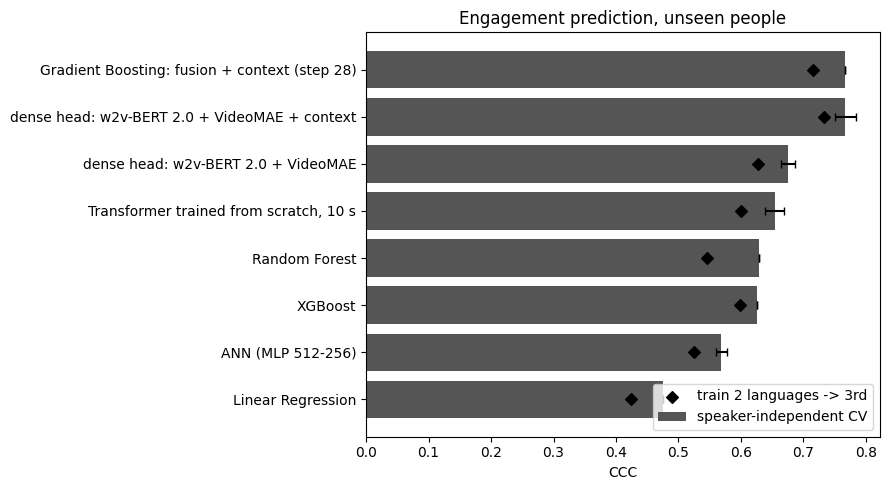

In [6]:
g = m.iloc[::-1]
lab = g['model'].str.slice(0, 48)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(lab, g['speaker_independent_ccc'], xerr=g['std_over_seeds'], color='#555555', capsize=3, label='speaker-independent CV')
ax.scatter(g['train_2_languages_to_3rd'], lab, color='black', marker='D', zorder=3, label='train 2 languages -> 3rd')
ax.set_xlabel('CCC'); ax.legend(loc='lower right'); ax.set_title('Engagement prediction, unseen people'); plt.tight_layout(); plt.show()

**Check against the saved results.**

In [7]:
saved = pd.read_csv('reports/final_models.csv')
print('models in step 29:', len(saved), '| best:', saved.sort_values('cv_ccc').iloc[-1]['model'])

models in step 29: 7 | best: dense head: w2v-BERT 2.0 + VideoMAE + context
